<a href="https://colab.research.google.com/github/cdameron101-web/blacksheep-labs-heart-disease-classification-/blob/main/Blacksheep_Labs_Heart_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
# Blacksheep Labs - Heart Disease Classification

# Import Pandas
import pandas as pd

# Import NumPy
import numpy as np

# Confirm the environment is ready
print("Blacksheep Labs ML Environment Ready!")

Blacksheep Labs ML Environment Ready!


In [21]:
!pip install Seaborn

In [22]:
# Step 2: Import visualization libraries

# Import Matplotlib and Pyplot
import matplotlib
import matplotlib.pyplot as plt

# Import Seaborn
import seaborn as sns

# Display installed library versions
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)

Matplotlib: 3.10.0
Seaborn: 0.13.2


In [23]:
# Step 3: Verify our machine learning environment

# Import scikit-learn
import sklearn

# Import a classification model
from sklearn.linear_model import LogisticRegression

# Display the installed version
print("Scikit-learn:", sklearn.__version__)

# Confirm our environment is ready
print("Blacksheep Labs ML Setup Complete!")

Scikit-learn: 1.6.1
Blacksheep Labs ML Setup Complete!


In [24]:
# Blacksheep Labs
# Heart Disease Classification Project

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

print("All project libraries imported successfully!")

All project libraries imported successfully!


In [25]:
import urllib.request
import os

# Define the dataset columns
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

# Path where the dataset will be saved
data_path = "/content/processed.cleveland.data"

# Download the dataset if it does not exist
if not os.path.exists(data_path):
    print("Downloading Cleveland heart disease dataset...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
    urllib.request.urlretrieve(url, data_path)
    print("Download complete!")

# Load the Cleveland heart disease dataset
df = pd.read_csv(
    data_path,
    header=None,
    names=columns,
    na_values="?"
)

# Display the first five patient records
print(df.head())

# Display the dataset dimensions
print("Dataset shape:", df.shape)

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  
Dataset shape: (303, 14)


In [26]:
# Step 3: Inspect our dataset

# Display column information
print("DATASET INFORMATION")
df.info()

# Check missing values
print("\nMISSING VALUES")
print(df.isna().sum())

# Count each heart disease category
print("\nTARGET DISTRIBUTION")
print(df["target"].value_counts())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

MISSING VALUES
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
t

In [27]:
# Blacksheep Labs
# Exploring Our Data — Step 1

# Display descriptive statistics
print("DATASET STATISTICS")
print(df.describe())

# Calculate average patient age
print("\nAVERAGE PATIENT AGE")
print(df["age"].mean())

# Find the highest cholesterol measurement
print("\nHIGHEST CHOLESTEROL")
print(df["chol"].max())

DATASET STATISTICS
              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  241.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  275.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  299.000000   
mean     0.990099  149.607261    0.326733    1.039604    1.600660    0.672241   
std     

In [28]:
# Blacksheep Labs
# Exploring Our Data — Step 2

# Create a binary heart disease column
df["heart_disease"] = (df["target"] > 0).astype(int)

# Count patients in each category
print("HEART DISEASE DISTRIBUTION")
print(df["heart_disease"].value_counts())

# Calculate the percentage in each category
print("\nHEART DISEASE PERCENTAGES")
print(df["heart_disease"].value_counts(normalize=True) * 100)

HEART DISEASE DISTRIBUTION
heart_disease
0    164
1    139
Name: count, dtype: int64

HEART DISEASE PERCENTAGES
heart_disease
0    54.125413
1    45.874587
Name: proportion, dtype: float64


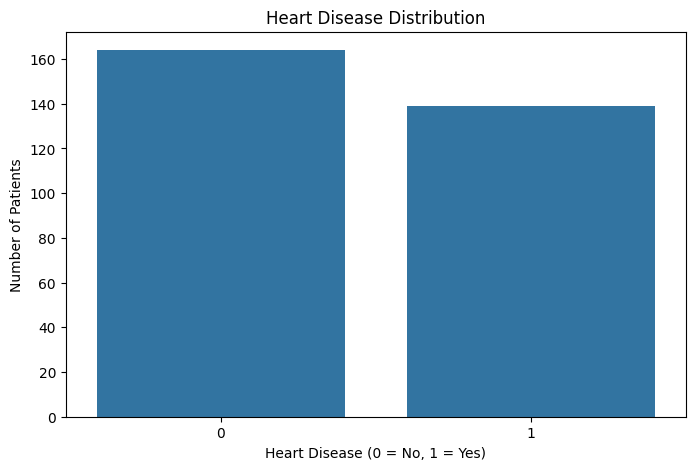

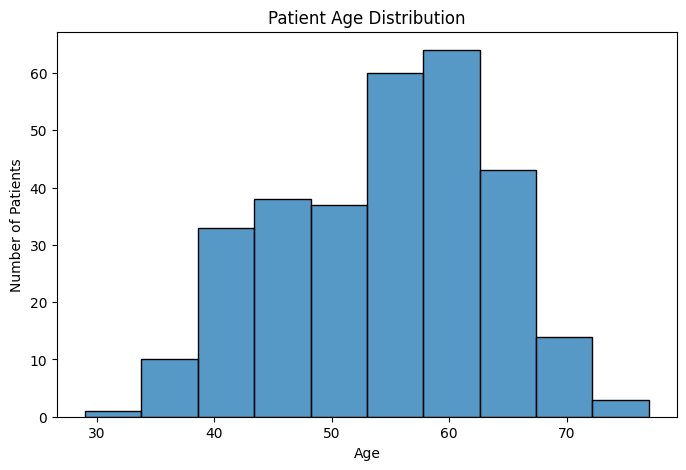

Average Patient Age: 54.44


In [29]:
# Blacksheep Labs
# Exploring Our Data — Step 3

# Chart 1: Heart disease distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="heart_disease"
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()


# Chart 2: Patient age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=10
)

plt.title("Patient Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()


# Display average patient age
print("Average Patient Age:", round(df["age"].mean(), 2))

AVERAGE AGE BY HEART DISEASE CATEGORY
heart_disease
0    52.585366
1    56.625899
Name: age, dtype: float64


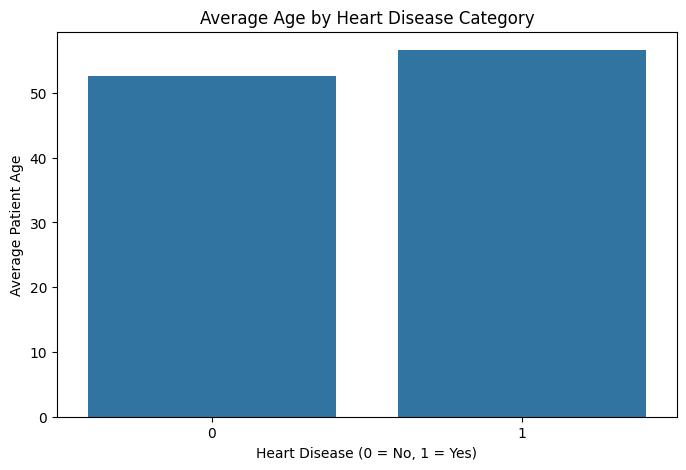

In [30]:
# Blacksheep Labs
# Finding Patterns — Step 1

# Calculate average age by heart disease category
average_age = df.groupby("heart_disease")["age"].mean()

print("AVERAGE AGE BY HEART DISEASE CATEGORY")
print(average_age)

# Visualize average patient age
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="heart_disease",
    y="age",
    estimator="mean",
    errorbar=None
)

plt.title("Average Age by Heart Disease Category")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Average Patient Age")
plt.show()

HEART DISEASE COUNTS BY SEX
heart_disease   0    1
sex                   
0.0            72   25
1.0            92  114

HEART DISEASE PERCENTAGES BY SEX
heart_disease      0      1
sex                        
0.0            74.23  25.77
1.0            44.66  55.34


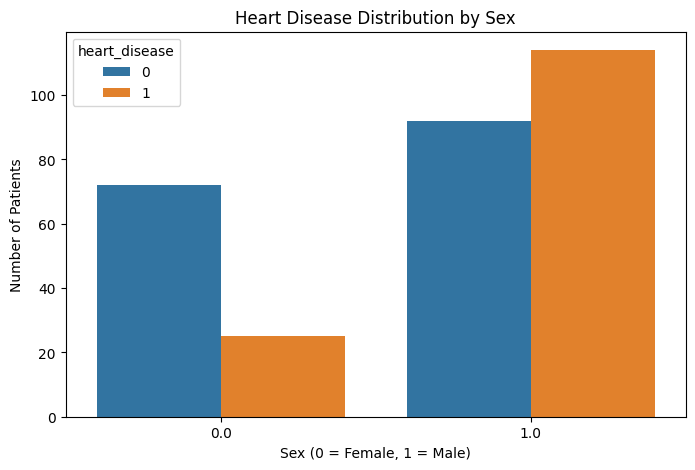

In [31]:
# Blacksheep Labs
# Finding Patterns — Step 2

# Count patients by sex and heart disease status
sex_counts = pd.crosstab(
    df["sex"],
    df["heart_disease"]
)

print("HEART DISEASE COUNTS BY SEX")
print(sex_counts)

# Calculate percentages within each sex category (corrected normalize argument to string)
sex_percentages = pd.crosstab(
    df["sex"],
    df["heart_disease"],
    normalize="index"
) * 100

print("\nHEART DISEASE PERCENTAGES BY SEX")
print(sex_percentages.round(2))

# Visualize patient counts
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="heart_disease"
)

plt.title("Heart Disease Distribution by Sex")
plt.xlabel("Sex (0 = Female, 1 = Male)")
plt.ylabel("Number of Patients")
plt.show()

AVERAGE MAXIMUM HEART RATE
heart_disease
0    158.38
1    139.26
Name: thalach, dtype: float64


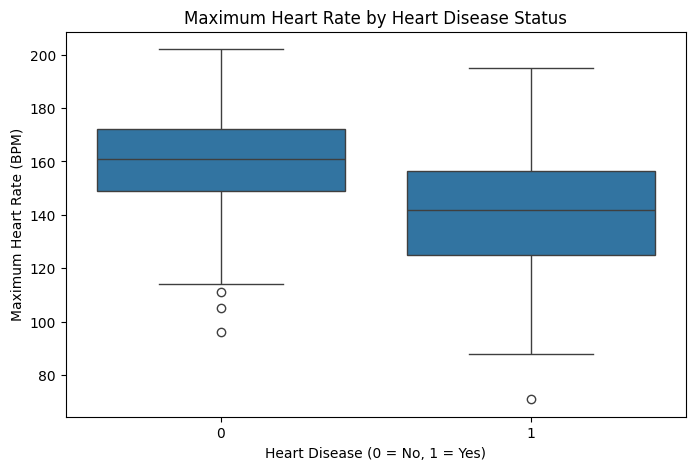

In [32]:
# Blacksheep Labs
# Finding Patterns — Step 3

# Calculate average maximum heart rate by disease status
heart_rate = df.groupby("heart_disease")["thalach"].mean()

print("AVERAGE MAXIMUM HEART RATE")
print(heart_rate.round(2))

# Create a box plot
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="heart_disease",
    y="thalach"
)

plt.title("Maximum Heart Rate by Heart Disease Status")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Maximum Heart Rate (BPM)")
plt.show()

In [33]:
# Blacksheep Labs
# Finding Patterns 2 — Step 1

# Note: Please ensure cell eETUKzLkX0cI is run first so 'df' is loaded.

# Select numerical measurements
features = ["age", "chol", "trestbps", "thalach"]

# Calculate correlation matrix
correlation_matrix = df[features].corr()

print("CORRELATION MATRIX")
print(correlation_matrix.round(2))

# Find correlation between age and max heart rate
age_heart_rate = df["age"].corr(df["thalach"])

print("\nAGE VS MAX HEART RATE CORRELATION")
# Corrected float() syntax error to round()
print(round(age_heart_rate, 2))

CORRELATION MATRIX
           age  chol  trestbps  thalach
age       1.00  0.21      0.28    -0.39
chol      0.21  1.00      0.13    -0.00
trestbps  0.28  0.13      1.00    -0.05
thalach  -0.39 -0.00     -0.05     1.00

AGE VS MAX HEART RATE CORRELATION
-0.39


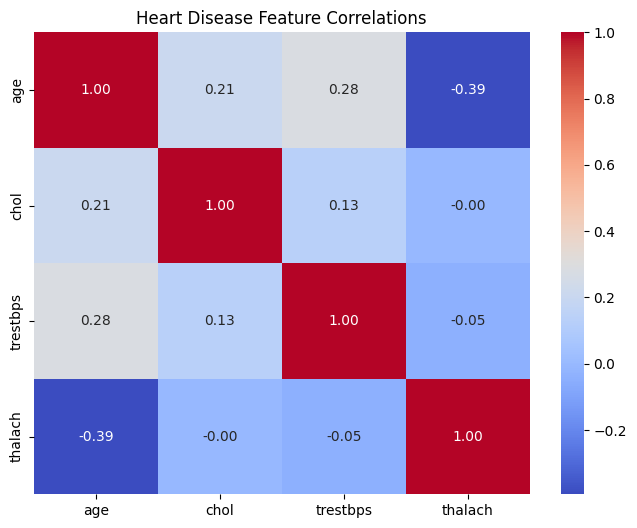

In [34]:
# Blacksheep Labs
# Finding Patterns 2 — Step 2

# Create the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Heart Disease Feature Correlations")
plt.show()

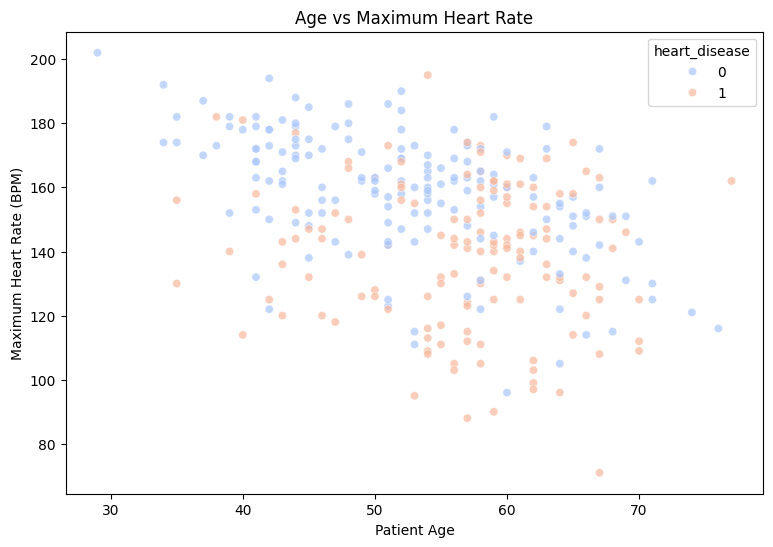

In [38]:
# Blacksheep Labs
# Finding Patterns 2 — Step 3

plt.figure(figsize=(9, 6))

# Create scatter plot
sns.scatterplot(
    data=df,
    x="age",
    y="thalach",
    hue="heart_disease",
    palette="coolwarm",
    alpha=0.7
)

plt.title("Age vs Maximum Heart Rate")
plt.xlabel("Patient Age")
plt.ylabel("Maximum Heart Rate (BPM)")
plt.show()

In [42]:
# Blacksheep Labs


# Count patients by exercise-induced angina
angina_counts = pd.crosstab(
    df["exang"],
    df["heart_disease"]
)

print("EXERCISE-INDUCED ANGINA COUNTS")
print(angina_counts)

# Calculate percentages within each angina group
angina_percentages = pd.crosstab(
    df["exang"],
    df["heart_disease"],
    normalize="index"
) * 100

print("\nHEART DISEASE PERCENTAGES BY ANGINA")
print(angina_percentages.round(2))

EXERCISE-INDUCED ANGINA COUNTS
heart_disease    0   1
exang                 
0.0            141  63
1.0             23  76

HEART DISEASE PERCENTAGES BY ANGINA
heart_disease      0      1
exang                      
0.0            69.12  30.88
1.0            23.23  76.77


Text(0.5, 1.0, 'Exercise-Induced')

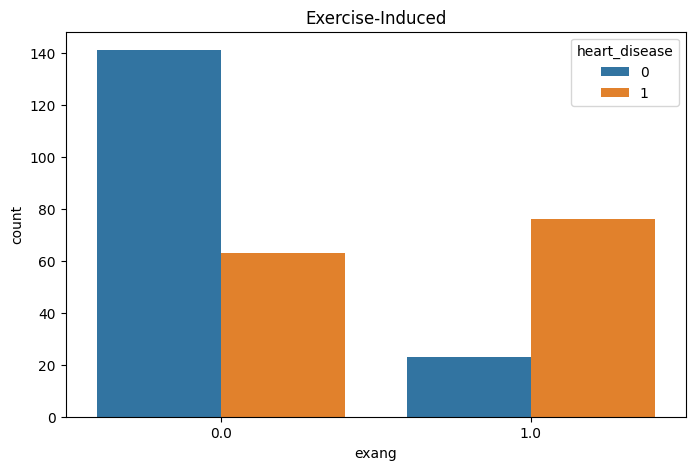

In [43]:
# Blacksheep Labs
# Finding Patterns 3 — Step 3

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="exang",
    hue="heart_disease"
)

plt.title("Exercise-Induced")

In [46]:
# Blacksheep Labs
# Preparing Our Data — Step 1

# Separate features from the target
X = df.drop(
    columns=["target", "heart_disease"]
)

# Select our binary classification target
y = df["heart_disease"]

# Check our results
print("FEATURES SHAPE:", X.shape)
print("TARGET SHAPE:", y.shape)

# Verify that the original target is excluded
print("\nFEATURE COLUMNS:")
print(X.columns.tolist())

FEATURES SHAPE: (303, 13)
TARGET SHAPE: (303,)

FEATURE COLUMNS:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [48]:
# Blacksheep Labs
# Preparing Our Data — Step 2

from sklearn.model_selection import train_test_split

# Split our dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the results
print("TRAINING FEATURES:", X_train.shape)
print("TESTING FEATURES:", X_test.shape)

print("\nTRAINING TARGET:", y_train.shape)
print("TESTING TARGET:", y_test.shape)

# Check heart disease percentages
print("\nTRAINING HEART DISEASE DISTRIBUTION:")
print(y_train.value_counts(normalize=True).round(2))

print("\nTESTING HEART DISEASE DISTRIBUTION:")
print(y_test.value_counts(normalize=True).round(2))

TRAINING FEATURES: (242, 13)
TESTING FEATURES: (61, 13)

TRAINING TARGET: (242,)
TESTING TARGET: (61,)

TRAINING HEART DISEASE DISTRIBUTION:
heart_disease
0    0.54
1    0.46
Name: proportion, dtype: float64

TESTING HEART DISEASE DISTRIBUTION:
heart_disease
0    0.54
1    0.46
Name: proportion, dtype: float64


In [49]:
# Blacksheep Labs
# Preparing Our Data — Step 3

from sklearn.impute import SimpleImputer
import pandas as pd

imputer = SimpleImputer(strategy="most_frequent")

# Learn from training data
X_train_clean = imputer.fit_transform(X_train)

# Apply what was learned to testing data
X_test_clean = imputer.transform(X_test)

# Convert back to DataFrames
X_train_clean = pd.DataFrame(
    X_train_clean,
    columns=X_train.columns
)

X_test_clean = pd.DataFrame(
    X_test_clean,
    columns=X_test.columns
)

# Check for missing values
print("TRAINING MISSING VALUES:",
      X_train_clean.isna().sum().sum())

print("TESTING MISSING VALUES:",
      X_test_clean.isna().sum().sum())

print("\nTraining shape:", X_train_clean.shape)
print("Testing shape:", X_test_clean.shape)

TRAINING MISSING VALUES: 0
TESTING MISSING VALUES: 0

Training shape: (242, 13)
Testing shape: (61, 13)


In [8]:
# Blacksheep Labs
# Experimenting With Models — Step 1
# COMPLETE STANDALONE CODE

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Load the Cleveland Heart Disease dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

# 2. Convert columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 3. Create binary classification target
# 0 = No heart disease
# 1 = Heart disease

df["heart_disease"] = (df["target"] > 0).astype(int)

# 4. Separate features and target
X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 5. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Create Logistic Regression pipeline
log_model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# 7. Train the model
log_model.fit(X_train, y_train)

# 8. Calculate training accuracy
training_accuracy = log_model.score(X_train, y_train)

# 9. Display results
print("BLACKSHEEP LABS")
print("LOGISTIC REGRESSION")
print("-------------------")
print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Training Accuracy:", round(training_accuracy, 4))

BLACKSHEEP LABS
LOGISTIC REGRESSION
-------------------
Total Samples: 303
Training Samples: 242
Testing Samples: 61
Training Accuracy: 0.8512


In [9]:
# Blacksheep Labs
# Experimenting With Models — Step 2

from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Create K-Nearest Neighbors model
knn_model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# 2. Create Random Forest model
rf_model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
)

# 3. Train both models
knn_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# 4. Calculate training accuracy
knn_accuracy = knn_model.score(X_train, y_train)
rf_accuracy = rf_model.score(X_train, y_train)

# 5. Compare all three models
print("BLACKSHEEP LABS")
print("MODEL COMPARISON")
print("----------------------------")

print("Logistic Regression:", round(training_accuracy, 4))
print("KNN:", round(knn_accuracy, 4))
print("Random Forest:", round(rf_accuracy, 4))

BLACKSHEEP LABS
MODEL COMPARISON
----------------------------
Logistic Regression: 0.8512
KNN: 0.8884
Random Forest: 1.0


In [10]:
# Blacksheep Labs
# Experimenting With Models — Step 3

import pandas as pd
from sklearn.metrics import accuracy_score

# 1. Make predictions on testing data
log_predictions = log_model.predict(X_test)
knn_predictions = knn_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# 2. Calculate testing accuracy
log_test_accuracy = accuracy_score(y_test, log_predictions)
knn_test_accuracy = accuracy_score(y_test, knn_predictions)
rf_test_accuracy = accuracy_score(y_test, rf_predictions)

# 3. Create comparison table
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "Random Forest"
    ],
    "Training Accuracy": [
        training_accuracy,
        knn_accuracy,
        rf_accuracy
    ],
    "Testing Accuracy": [
        log_test_accuracy,
        knn_test_accuracy,
        rf_test_accuracy
    ]
})

# 4. Display results
print("BLACKSHEEP LABS")
print("FINAL MODEL COMPARISON")
print("-----------------------------")

print(results.round(4).to_string(index=False))

# 5. Calculate training/testing accuracy gap
results["Accuracy Gap"] = (
    results["Training Accuracy"] -
    results["Testing Accuracy"]
)

print("\nOVERFITTING CHECK")
print("-----------------------------")

print(
    results[
        ["Model", "Accuracy Gap"]
    ].round(4).to_string(index=False)
)

BLACKSHEEP LABS
FINAL MODEL COMPARISON
-----------------------------
              Model  Training Accuracy  Testing Accuracy
Logistic Regression             0.8512            0.8689
                KNN             0.8884            0.8852
      Random Forest             1.0000            0.8852

OVERFITTING CHECK
-----------------------------
              Model  Accuracy Gap
Logistic Regression       -0.0176
                KNN        0.0032
      Random Forest        0.1148


In [11]:
# Blacksheep Labs
# Tuning Hyperparameters — Step 1 of 3

import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Hyperparameter values to test
neighbor_values = [1, 3, 5, 7, 9, 11, 13, 15]

# Store our results
knn_results = []

# Use 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Test different KNN settings
for neighbors in neighbor_values:

    model = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=neighbors)
    )

    # Evaluate using training data only
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    knn_results.append({
        "Neighbors": neighbors,
        "Average CV Accuracy": scores.mean()
    })

# Create results table
knn_results_df = pd.DataFrame(knn_results)

print("BLACKSHEEP LABS")
print("KNN HYPERPARAMETER TUNING")
print("--------------------------------")

print(knn_results_df.round(4).to_string(index=False))

# Identify the best setting
best_row = knn_results_df.loc[
    knn_results_df["Average CV Accuracy"].idxmax()
]

best_neighbors = int(best_row["Neighbors"])

print("\nBEST KNN SETTINGS")
print("--------------------------------")
print("Best Number of Neighbors:", best_neighbors)
print(
    "Best Average CV Accuracy:",
    round(best_row["Average CV Accuracy"], 4)
)

BLACKSHEEP LABS
KNN HYPERPARAMETER TUNING
--------------------------------
 Neighbors  Average CV Accuracy
         1               0.7520
         3               0.8139
         5               0.8223
         7               0.8099
         9               0.8058
        11               0.8308
        13               0.8308
        15               0.8349

BEST KNN SETTINGS
--------------------------------
Best Number of Neighbors: 15
Best Average CV Accuracy: 0.8349


In [12]:
# Blacksheep Labs
# Tuning Hyperparameters — Step 2 of 3

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# 1. Create tuned KNN model
tuned_knn_model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=best_neighbors)
)

# 2. Train tuned model
tuned_knn_model.fit(X_train, y_train)

# 3. Calculate training accuracy
tuned_training_accuracy = tuned_knn_model.score(
    X_train,
    y_train
)

# 4. Retrieve cross-validation results from Step 1
best_cv_accuracy = knn_results_df[
    knn_results_df["Neighbors"] == best_neighbors
]["Average CV Accuracy"].iloc[0]

# 5. Display results
print("BLACKSHEEP LABS")
print("TUNED KNN MODEL")
print("------------------------------")

print("Number of Neighbors:", best_neighbors)
print("Training Accuracy:", round(tuned_training_accuracy, 4))
print("Average CV Accuracy:", round(best_cv_accuracy, 4))

print("\nMODEL TRAINING COMPLETE!")

BLACKSHEEP LABS
TUNED KNN MODEL
------------------------------
Number of Neighbors: 15
Training Accuracy: 0.8554
Average CV Accuracy: 0.8349

MODEL TRAINING COMPLETE!


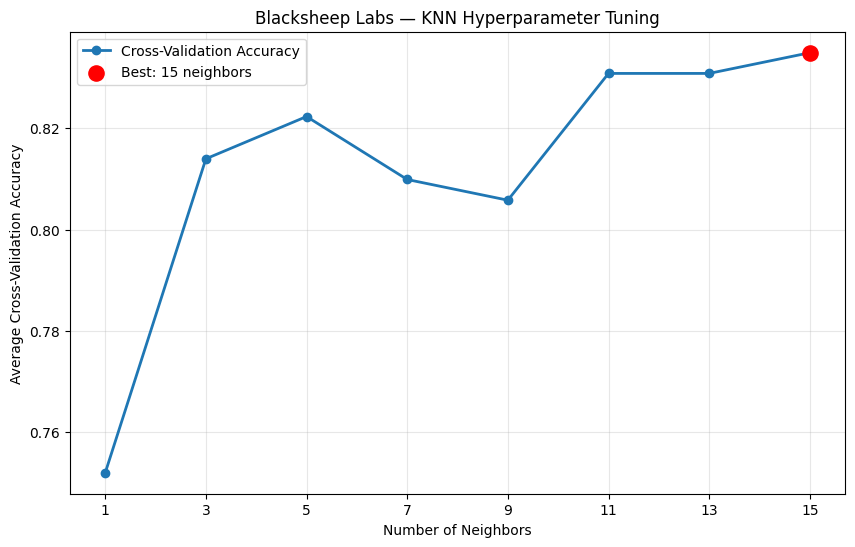

BLACKSHEEP LABS
HYPERPARAMETER TUNING SUMMARY
--------------------------------
Original Neighbors: 5
Tuned Neighbors: 15
Original CV Accuracy: 0.8223
Tuned CV Accuracy: 0.8349


In [13]:
# Blacksheep Labs
# Tuning Hyperparameters — Step 3 of 3

import matplotlib.pyplot as plt

# Use the results from Step 1
neighbors = knn_results_df["Neighbors"]
accuracy = knn_results_df["Average CV Accuracy"]

# Create visualization
plt.figure(figsize=(10, 6))

plt.plot(
    neighbors,
    accuracy,
    marker="o",
    linewidth=2,
    label="Cross-Validation Accuracy"
)

# Highlight the best hyperparameter
plt.scatter(
    best_neighbors,
    best_cv_accuracy,
    color="red",
    s=120,
    zorder=5,
    label=f"Best: {best_neighbors} neighbors"
)

# Add chart labels
plt.title("Blacksheep Labs — KNN Hyperparameter Tuning")
plt.xlabel("Number of Neighbors")
plt.ylabel("Average Cross-Validation Accuracy")
plt.xticks(neighbor_values)
plt.grid(True, alpha=0.3)
plt.legend()

# Display chart
plt.show()

# Print summary
print("BLACKSHEEP LABS")
print("HYPERPARAMETER TUNING SUMMARY")
print("--------------------------------")
print("Original Neighbors: 5")
print("Tuned Neighbors:", best_neighbors)
print("Original CV Accuracy: 0.8223")
print("Tuned CV Accuracy:", round(best_cv_accuracy, 4))

In [2]:
# Blacksheep Labs
# Lesson 15: Tuning Hyperparameters 2
# Step 1 of 3 — Complete GridSearchCV

import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# 1. Load the heart disease dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

# 2. Convert all columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# 3. Create binary target
df["heart_disease"] = (
    df["target"] > 0
).astype(int)

# 4. Separate features and target
X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 5. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Create KNN pipeline
knn_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    StandardScaler(),
    KNeighborsClassifier()
)

# 7. Define hyperparameters
param_grid = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 11, 15],
    "kneighborsclassifier__weights": [
        "uniform",
        "distance"
    ]
}

# 8. Set up cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 9. Create GridSearchCV
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# 10. Train and search
grid_search.fit(X_train, y_train)

# 11. Display results
print("BLACKSHEEP LABS")
print("GRID SEARCH RESULTS")
print("--------------------------------")

print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nBest Parameters:", grid_search.best_params_)
print(
    "Best CV Accuracy:",
    round(grid_search.best_score_, 4)
)
print(
    "Total Combinations Tested:",
    len(grid_search.cv_results_["params"])
)

BLACKSHEEP LABS
GRID SEARCH RESULTS
--------------------------------
Total Samples: 303
Training Samples: 242
Testing Samples: 61

Best Parameters: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'uniform'}
Best CV Accuracy: 0.8349
Total Combinations Tested: 10


In [3]:
# Blacksheep Labs
# Lesson 15: Tuning Hyperparameters 2
# Step 2 of 3 — Examine GridSearchCV Results

import pandas as pd

# Extract results from GridSearchCV
grid_results = pd.DataFrame(grid_search.cv_results_)

# Select useful columns
comparison = grid_results[
    [
        "param_kneighborsclassifier__n_neighbors",
        "param_kneighborsclassifier__weights",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]
].copy()

# Rename columns
comparison.columns = [
    "Neighbors",
    "Weights",
    "Average CV Accuracy",
    "CV Standard Deviation",
    "Rank"
]

# Sort by highest accuracy
comparison = comparison.sort_values(
    by="Average CV Accuracy",
    ascending=False
)

# Display results
print("BLACKSHEEP LABS")
print("GRID SEARCH COMPARISON")
print("--------------------------------")

print(comparison.round(4).to_string(index=False))

print("\nBEST MODEL SETTINGS")
print("--------------------------------")
print("Neighbors:", grid_search.best_params_[
    "kneighborsclassifier__n_neighbors"
])
print("Weights:", grid_search.best_params_[
    "kneighborsclassifier__weights"
])
print("Average CV Accuracy:", round(grid_search.best_score_, 4))

BLACKSHEEP LABS
GRID SEARCH COMPARISON
--------------------------------
 Neighbors  Weights  Average CV Accuracy  CV Standard Deviation  Rank
        15  uniform               0.8349                 0.0443     1
        11  uniform               0.8308                 0.0500     2
        15 distance               0.8265                 0.0417     3
        11 distance               0.8224                 0.0471     4
         5  uniform               0.8223                 0.0249     5
         5 distance               0.8182                 0.0300     6
         3  uniform               0.8139                 0.0371     7
         3 distance               0.8099                 0.0419     8
         7  uniform               0.8099                 0.0398     9
         7 distance               0.8058                 0.0458    10

BEST MODEL SETTINGS
--------------------------------
Neighbors: 15
Weights: uniform
Average CV Accuracy: 0.8349


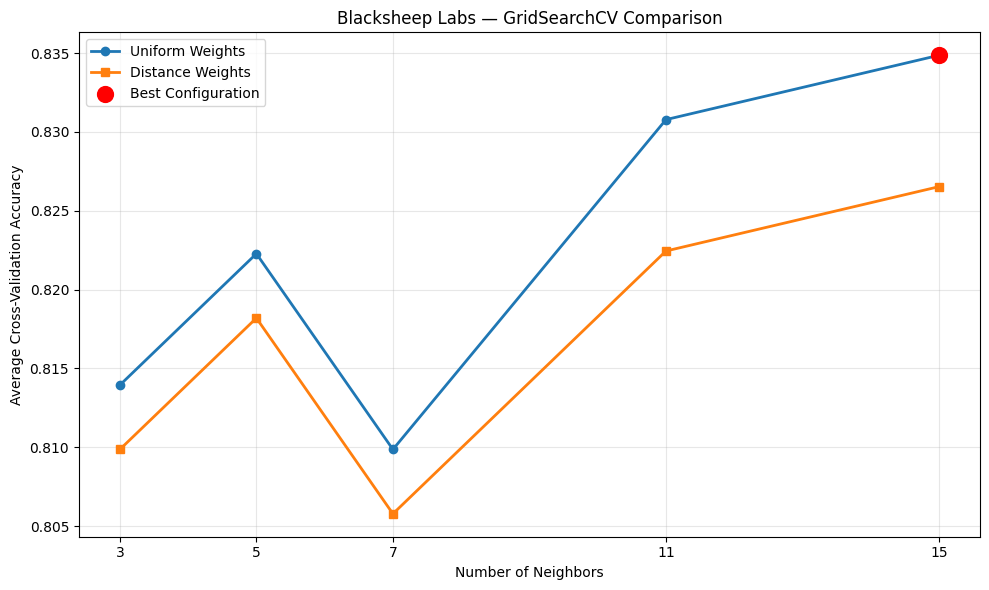

BLACKSHEEP LABS
GRID SEARCH SUMMARY
------------------------------
Best Neighbors: 15
Best Weights: uniform
Best CV Accuracy: 0.8349


In [4]:
# Blacksheep Labs
# Lesson 15: Tuning Hyperparameters 2
# Step 3 of 3 — Visualizing GridSearchCV

import matplotlib.pyplot as plt

# Use the comparison table from Step 2
uniform_results = comparison[
    comparison["Weights"] == "uniform"
].sort_values("Neighbors")

distance_results = comparison[
    comparison["Weights"] == "distance"
].sort_values("Neighbors")

# Create chart
plt.figure(figsize=(10, 6))

plt.plot(
    uniform_results["Neighbors"],
    uniform_results["Average CV Accuracy"],
    marker="o",
    linewidth=2,
    label="Uniform Weights"
)

plt.plot(
    distance_results["Neighbors"],
    distance_results["Average CV Accuracy"],
    marker="s",
    linewidth=2,
    label="Distance Weights"
)

# Highlight best configuration
plt.scatter(
    grid_search.best_params_[
        "kneighborsclassifier__n_neighbors"
    ],
    grid_search.best_score_,
    color="red",
    s=130,
    zorder=5,
    label="Best Configuration"
)

# Add labels
plt.title("Blacksheep Labs — GridSearchCV Comparison")
plt.xlabel("Number of Neighbors")
plt.ylabel("Average Cross-Validation Accuracy")
plt.xticks([3, 5, 7, 11, 15])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Display chart
plt.show()

# Display summary
print("BLACKSHEEP LABS")
print("GRID SEARCH SUMMARY")
print("------------------------------")
print("Best Neighbors:", grid_search.best_params_[
    "kneighborsclassifier__n_neighbors"
])
print("Best Weights:", grid_search.best_params_[
    "kneighborsclassifier__weights"
])
print("Best CV Accuracy:", round(grid_search.best_score_, 4))

In [5]:
# Blacksheep Labs
# Lesson 16: Tuning Hyperparameters 3
# Step 1 of 3 — RandomizedSearchCV

import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# 1. Load the Cleveland Heart Disease dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

# 2. Convert all columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 3. Create binary classification target
df["heart_disease"] = (df["target"] > 0).astype(int)

# 4. Separate features and target
X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 5. Split data using the same settings as earlier lessons
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Create Random Forest pipeline
rf_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(random_state=42)
)

# 7. Define hyperparameters to explore
param_distributions = {
    "randomforestclassifier__n_estimators": [50, 100, 200],
    "randomforestclassifier__max_depth": [3, 5, 10, None],
    "randomforestclassifier__min_samples_split": [2, 5, 10],
    "randomforestclassifier__min_samples_leaf": [1, 2, 4]
}

# 8. Set up cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 9. Create randomized search
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    cv=cv,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

# 10. Run hyperparameter search
random_search.fit(X_train, y_train)

# 11. Display results
print("BLACKSHEEP LABS")
print("RANDOM FOREST HYPERPARAMETER TUNING")
print("----------------------------------------")

print("Total Samples:", len(df))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nBest Parameters:")
for parameter, value in random_search.best_params_.items():
    print(parameter, ":", value)

print(
    "\nBest CV Accuracy:",
    round(random_search.best_score_, 4)
)

print(
    "Configurations Tested:",
    len(random_search.cv_results_["params"])
)

BLACKSHEEP LABS
RANDOM FOREST HYPERPARAMETER TUNING
----------------------------------------
Total Samples: 303
Training Samples: 242
Testing Samples: 61

Best Parameters:
randomforestclassifier__n_estimators : 100
randomforestclassifier__min_samples_split : 2
randomforestclassifier__min_samples_leaf : 2
randomforestclassifier__max_depth : 3

Best CV Accuracy: 0.8224
Configurations Tested: 20


In [6]:
# Blacksheep Labs
# Lesson 16: Tuning Hyperparameters 3
# Step 2 of 3 — Examine Tuned Random Forest

import pandas as pd

# 1. Retrieve the best model
tuned_rf_model = random_search.best_estimator_

# 2. Calculate training accuracy
tuned_rf_training_accuracy = tuned_rf_model.score(
    X_train,
    y_train
)

# 3. Retrieve cross-validation accuracy
tuned_rf_cv_accuracy = random_search.best_score_

# 4. Create a results table
rf_results = pd.DataFrame(random_search.cv_results_)

comparison = rf_results[
    [
        "param_randomforestclassifier__n_estimators",
        "param_randomforestclassifier__max_depth",
        "param_randomforestclassifier__min_samples_split",
        "param_randomforestclassifier__min_samples_leaf",
        "mean_test_score",
        "rank_test_score"
    ]
].copy()

# 5. Rename columns
comparison.columns = [
    "Trees",
    "Max Depth",
    "Min Samples Split",
    "Min Samples Leaf",
    "Average CV Accuracy",
    "Rank"
]

# 6. Sort by rank
comparison = comparison.sort_values("Rank")

# 7. Display results
print("BLACKSHEEP LABS")
print("TUNED RANDOM FOREST RESULTS")
print("--------------------------------")

print("Training Accuracy:", round(tuned_rf_training_accuracy, 4))
print("Average CV Accuracy:", round(tuned_rf_cv_accuracy, 4))

print("\nTOP 5 CONFIGURATIONS")
print("--------------------------------")
print(comparison.head(5).round(4).to_string(index=False))

print("\nTUNED MODEL READY!")

BLACKSHEEP LABS
TUNED RANDOM FOREST RESULTS
--------------------------------
Training Accuracy: 0.8595
Average CV Accuracy: 0.8224

TOP 5 CONFIGURATIONS
--------------------------------
 Trees Max Depth  Min Samples Split  Min Samples Leaf  Average CV Accuracy  Rank
   100         3                  2                 2               0.8224     1
   200         3                  2                 2               0.8223     2
   100         3                  5                 1               0.8182     3
    50         3                  2                 4               0.8181     4
    50         3                  2                 1               0.8180     5

TUNED MODEL READY!


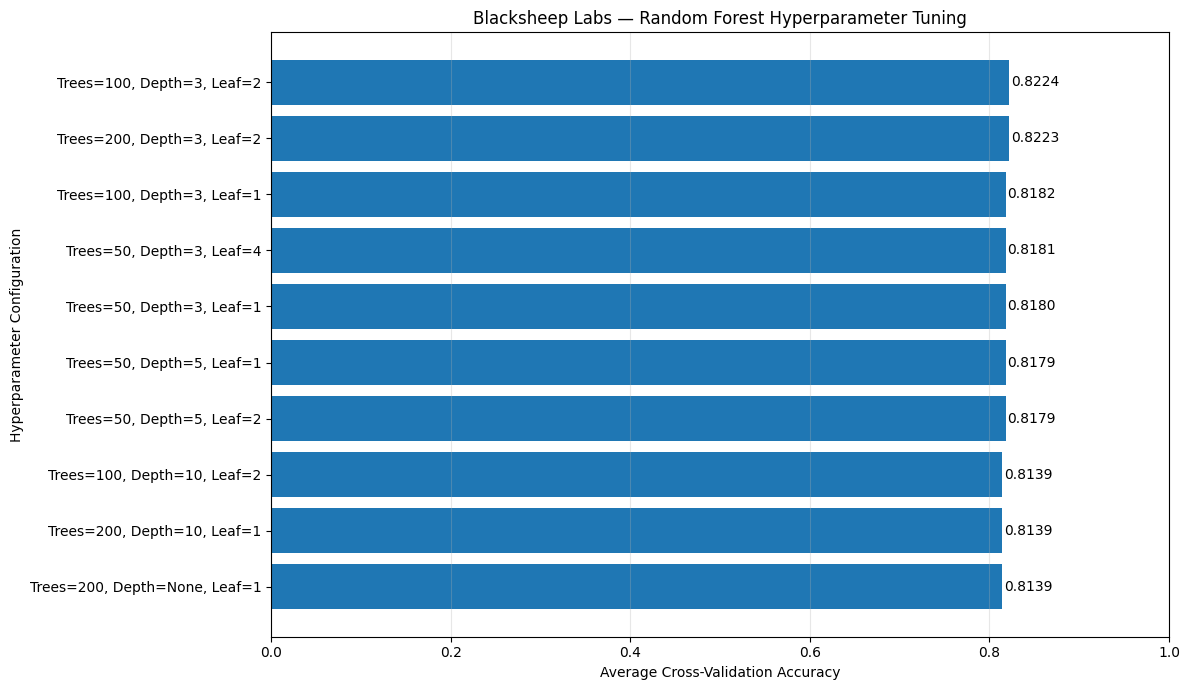

BLACKSHEEP LABS
RANDOM FOREST TUNING SUMMARY
--------------------------------
Configurations Tested: 20
Best CV Accuracy: 0.8224
Tuned Training Accuracy: 0.8595

BEST HYPERPARAMETERS
randomforestclassifier__n_estimators : 100
randomforestclassifier__min_samples_split : 2
randomforestclassifier__min_samples_leaf : 2
randomforestclassifier__max_depth : 3


In [7]:
# Blacksheep Labs
# Lesson 16: Tuning Hyperparameters 3
# Step 3 of 3 — Visualize Random Forest Tuning

import matplotlib.pyplot as plt

# 1. Select the top 10 configurations
top_10 = comparison.head(10).copy()

# 2. Create labels for each configuration
top_10["Configuration"] = [
    f"Trees={row['Trees']}, Depth={row['Max Depth']}, "
    f"Leaf={row['Min Samples Leaf']}"
    for _, row in top_10.iterrows()
]

# 3. Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10["Configuration"],
    top_10["Average CV Accuracy"]
)

# 4. Add chart labels
plt.title("Blacksheep Labs — Random Forest Hyperparameter Tuning")
plt.xlabel("Average Cross-Validation Accuracy")
plt.ylabel("Hyperparameter Configuration")

# Show highest-scoring configuration at top
plt.gca().invert_yaxis()

# Add accuracy labels
for i, accuracy in enumerate(top_10["Average CV Accuracy"]):
    plt.text(
        accuracy + 0.002,
        i,
        f"{accuracy:.4f}",
        va="center"
    )

plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Display final summary
print("BLACKSHEEP LABS")
print("RANDOM FOREST TUNING SUMMARY")
print("--------------------------------")

print("Configurations Tested:", len(comparison))
print("Best CV Accuracy:", round(random_search.best_score_, 4))
print("Tuned Training Accuracy:", round(tuned_rf_training_accuracy, 4))

print("\nBEST HYPERPARAMETERS")
for parameter, value in random_search.best_params_.items():
    print(parameter, ":", value)

In [8]:
# Blacksheep Labs
# Lesson 17: Evaluating Our Model
# Step 1 of 3 — Classification Metrics

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Load heart disease dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

# 2. Convert data to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 3. Create binary target
df["heart_disease"] = (df["target"] > 0).astype(int)

X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 4. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Build tuned Random Forest
model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42
    )
)

# 6. Train model
model.fit(X_train, y_train)

# 7. Predict unseen testing data
y_predictions = model.predict(X_test)

# 8. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_predictions)
precision = precision_score(y_test, y_predictions)
recall = recall_score(y_test, y_predictions)
f1 = f1_score(y_test, y_predictions)

# 9. Display results
print("BLACKSHEEP LABS")
print("HEART DISEASE CLASSIFICATION EVALUATION")
print("----------------------------------------")

print("Testing Samples:", len(X_test))
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

BLACKSHEEP LABS
HEART DISEASE CLASSIFICATION EVALUATION
----------------------------------------
Testing Samples: 61
Accuracy: 0.918
Precision: 0.8966
Recall: 0.9286
F1 Score: 0.9123


BLACKSHEEP LABS
HEART DISEASE CONFUSION MATRIX
--------------------------------
True Negatives: 30
False Positives: 3
False Negatives: 2
True Positives: 26

CONFUSION MATRIX:
[[30  3]
 [ 2 26]]


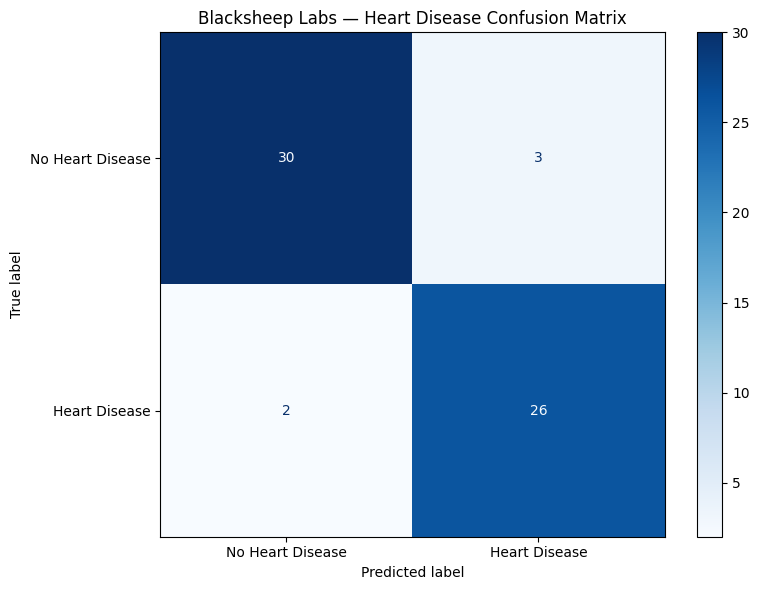


TOTAL TEST PREDICTIONS: 61
CORRECT PREDICTIONS: 56
INCORRECT PREDICTIONS: 5


In [9]:
# Blacksheep Labs
# Lesson 17: Evaluating Our Model
# Step 2 of 3 — Confusion Matrix

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Calculate confusion matrix
cm = confusion_matrix(y_test, y_predictions)

# 2. Extract the four results
tn, fp, fn, tp = cm.ravel()

# 3. Display numerical results
print("BLACKSHEEP LABS")
print("HEART DISEASE CONFUSION MATRIX")
print("--------------------------------")

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nCONFUSION MATRIX:")
print(cm)

# 4. Create visualization
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Heart Disease",
        "Heart Disease"
    ]
)

fig, ax = plt.subplots(figsize=(8, 6))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

plt.title("Blacksheep Labs — Heart Disease Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. Display total predictions
print("\nTOTAL TEST PREDICTIONS:", cm.sum())
print("CORRECT PREDICTIONS:", tn + tp)
print("INCORRECT PREDICTIONS:", fp + fn)

In [10]:
# Blacksheep Labs
# Lesson 17: Evaluating Our Model
# Step 3 of 3 — Final Classification Report

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# 1. Generate classification report
print("BLACKSHEEP LABS")
print("FINAL CLASSIFICATION REPORT")
print("--------------------------------")

print(
    classification_report(
        y_test,
        y_predictions,
        target_names=[
            "No Heart Disease",
            "Heart Disease"
        ],
        zero_division=0
    )
)

# 2. Display confusion matrix breakdown
tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_predictions,
    labels=[0, 1]
).ravel()

print("CONFUSION MATRIX BREAKDOWN")
print("--------------------------------")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

# 3. Display final model summary
print("\nFINAL MODEL SUMMARY")
print("--------------------------------")
print("Model: Tuned Random Forest")
print("Testing Samples:", len(y_test))
print("Correct Predictions:", tn + tp)
print("Incorrect Predictions:", fp + fn)
print(
    "Test Accuracy:",
    round(accuracy_score(y_test, y_predictions), 4)
)

print("\nBLACKSHEEP LABS — EVALUATION COMPLETE!")

BLACKSHEEP LABS
FINAL CLASSIFICATION REPORT
--------------------------------
                  precision    recall  f1-score   support

No Heart Disease       0.94      0.91      0.92        33
   Heart Disease       0.90      0.93      0.91        28

        accuracy                           0.92        61
       macro avg       0.92      0.92      0.92        61
    weighted avg       0.92      0.92      0.92        61

CONFUSION MATRIX BREAKDOWN
--------------------------------
True Negatives: 30
False Positives: 3
False Negatives: 2
True Positives: 26

FINAL MODEL SUMMARY
--------------------------------
Model: Tuned Random Forest
Testing Samples: 61
Correct Predictions: 56
Incorrect Predictions: 5
Test Accuracy: 0.918

BLACKSHEEP LABS — EVALUATION COMPLETE!


In [11]:
# Blacksheep Labs
# Lesson 18: Evaluating Our Model 2
# Step 1 of 3 — Calculate ROC AUC

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

# 1. Load the dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

# 2. Convert columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 3. Create binary target
df["heart_disease"] = (df["target"] > 0).astype(int)

X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 4. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Build tuned Random Forest
model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42
    )
)

# 6. Train model
model.fit(X_train, y_train)

# 7. Get predicted probabilities for heart disease
y_probabilities = model.predict_proba(X_test)[:, 1]

# 8. Calculate ROC AUC
auc_score = roc_auc_score(y_test, y_probabilities)

# 9. Display results
print("BLACKSHEEP LABS")
print("ROC AUC EVALUATION")
print("--------------------------------")

print("Testing Samples:", len(X_test))
print("ROC AUC Score:", round(auc_score, 4))

print("\nFIRST 5 PREDICTED PROBABILITIES:")
print(y_probabilities[:5])

BLACKSHEEP LABS
ROC AUC EVALUATION
--------------------------------
Testing Samples: 61
ROC AUC Score: 0.9675

FIRST 5 PREDICTED PROBABILITIES:
[0.25639861 0.57079077 0.13825285 0.12237796 0.36771821]


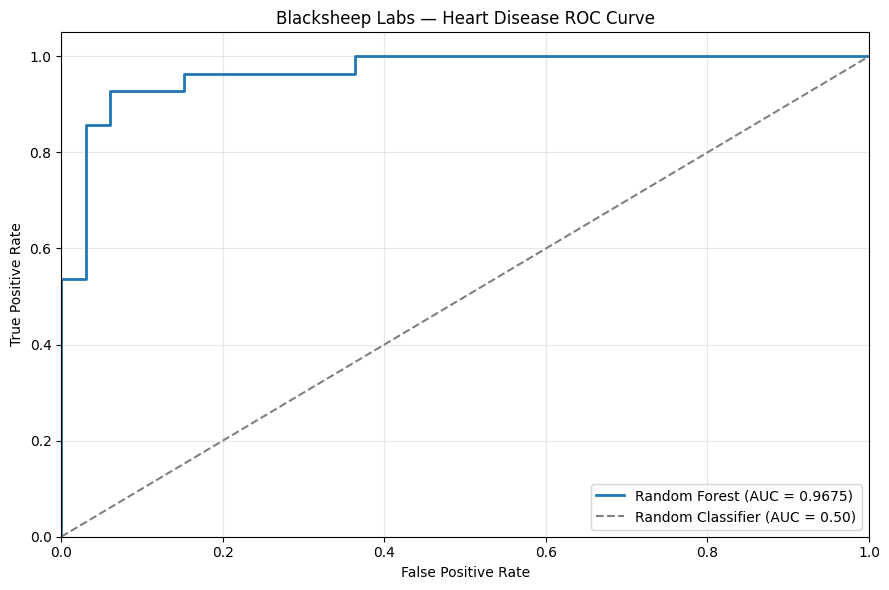

BLACKSHEEP LABS
ROC CURVE RESULTS
--------------------------------
ROC AUC Score: 0.9675
ROC Curve Points: 12
ROC Curve Created Successfully!


In [12]:
# Blacksheep Labs
# Lesson 18: Evaluating Our Model 2
# Step 2 of 3 — Plot ROC Curve

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# 1. Calculate ROC curve points
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probabilities
)

# 2. Calculate AUC
auc_score = roc_auc_score(
    y_test,
    y_probabilities
)

# 3. Create ROC curve
plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

# 4. Add random-classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.50)"
)

# 5. Add labels
plt.title("Blacksheep Labs — Heart Disease ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

# 6. Display chart
plt.show()

# 7. Display summary
print("BLACKSHEEP LABS")
print("ROC CURVE RESULTS")
print("--------------------------------")
print("ROC AUC Score:", round(auc_score, 4))
print("ROC Curve Points:", len(fpr))
print("ROC Curve Created Successfully!")

In [13]:
# Blacksheep Labs
# Lesson 18: Evaluating Our Model 2
# Step 3 of 3 — Comparing Classification Thresholds

import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 1. Define thresholds to compare
thresholds_to_test = [0.30, 0.50, 0.70]

results = []

# 2. Evaluate each threshold
for threshold in thresholds_to_test:

    # Convert probabilities into predictions
    predictions = (
        y_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    # Store evaluation metrics
    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

# 3. Create comparison table
threshold_results = pd.DataFrame(results)

print("BLACKSHEEP LABS")
print("CLASSIFICATION THRESHOLD COMPARISON")
print("----------------------------------------")

print(
    threshold_results.round(4).to_string(index=False)
)

# 4. Display final ROC AUC
print("\nFINAL ROC AUC:", round(auc_score, 4))

print("\nTHRESHOLD COMPARISON COMPLETE!")

BLACKSHEEP LABS
CLASSIFICATION THRESHOLD COMPARISON
----------------------------------------
 Threshold  Accuracy  Precision  Recall  F1 Score  False Positives  False Negatives
       0.3    0.7869     0.6829  1.0000    0.8116               13                0
       0.5    0.9180     0.8966  0.9286    0.9123                3                2
       0.7    0.8197     0.9474  0.6429    0.7660                1               10

FINAL ROC AUC: 0.9675

THRESHOLD COMPARISON COMPLETE!


In [14]:
# Blacksheep Labs
# Lesson 19: Evaluating Our Model 3
# Step 1 of 3 — Multiple-Metric Cross-Validation

import pandas as pd

from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# 1. Load dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

# 2. Convert columns to numeric
for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# 3. Create binary target
df["heart_disease"] = (df["target"] > 0).astype(int)

X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 4. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Create tuned Random Forest
model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42
    )
)

# 6. Define five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 7. Define evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# 8. Run cross-validation on training data
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# 9. Display results
print("BLACKSHEEP LABS")
print("MULTIPLE-METRIC CROSS-VALIDATION")
print("----------------------------------------")

print("Training Samples:", len(X_train))
print("Cross-Validation Folds:", cv.get_n_splits())

print("\nAVERAGE CROSS-VALIDATION SCORES")
print("----------------------------------------")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f}"
    )

print("\nCROSS-VALIDATION COMPLETE!")

BLACKSHEEP LABS
MULTIPLE-METRIC CROSS-VALIDATION
----------------------------------------
Training Samples: 242
Cross-Validation Folds: 5

AVERAGE CROSS-VALIDATION SCORES
----------------------------------------
ACCURACY: 0.8224
PRECISION: 0.8620
RECALL: 0.7379
F1: 0.7905
ROC_AUC: 0.8928

CROSS-VALIDATION COMPLETE!


BLACKSHEEP LABS
INDIVIDUAL CROSS-VALIDATION FOLDS
----------------------------------------
 Fold  Accuracy  Precision  Recall  F1 Score  ROC AUC
    1    0.8367     0.8261  0.8261    0.8261   0.9398
    2    0.7959     0.8750  0.6364    0.7368   0.8771
    3    0.8333     0.9375  0.6818    0.7895   0.8864
    4    0.8125     0.7826  0.8182    0.8000   0.8916
    5    0.8333     0.8889  0.7273    0.8000   0.8689

CROSS-VALIDATION SUMMARY
----------------------------------------
Accuracy: Average = 0.8224, Std Dev = 0.0158
Precision: Average = 0.8620, Std Dev = 0.0533
Recall: Average = 0.7379, Std Dev = 0.0746
F1 Score: Average = 0.7905, Std Dev = 0.0294
ROC AUC: Average = 0.8928, Std Dev = 0.0248


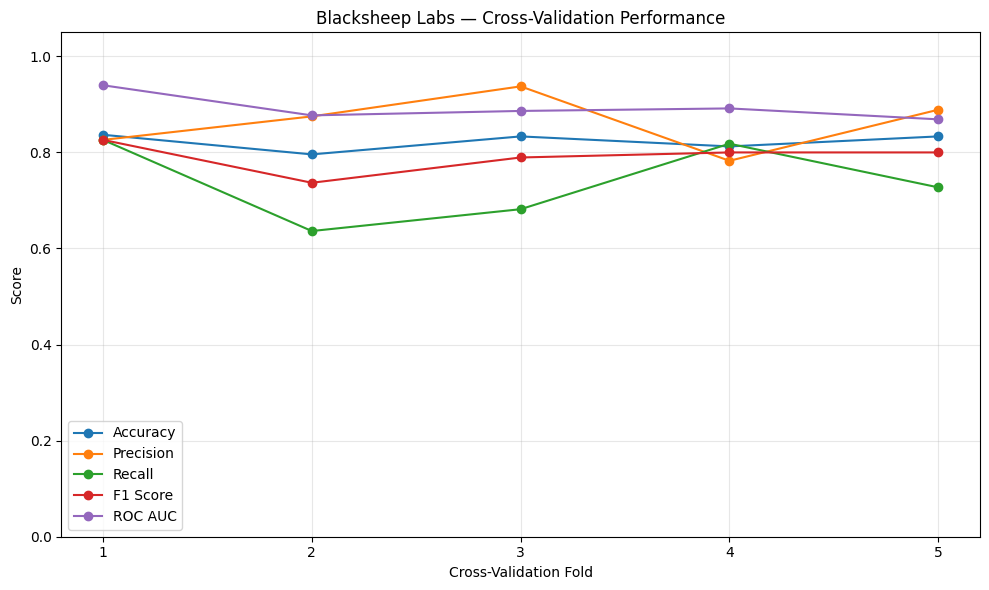


FOLD ANALYSIS COMPLETE!


In [15]:
# Blacksheep Labs
# Lesson 19: Evaluating Our Model 3
# Step 2 of 3 — Individual Cross-Validation Results

import pandas as pd
import matplotlib.pyplot as plt

# 1. Create a table of individual fold scores
fold_results = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1 Score": cv_results["test_f1"],
    "ROC AUC": cv_results["test_roc_auc"]
})

# 2. Display individual fold results
print("BLACKSHEEP LABS")
print("INDIVIDUAL CROSS-VALIDATION FOLDS")
print("----------------------------------------")

print(fold_results.round(4).to_string(index=False))

# 3. Calculate averages and standard deviations
print("\nCROSS-VALIDATION SUMMARY")
print("----------------------------------------")

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC AUC"
]

for metric in metrics:
    average = fold_results[metric].mean()
    std = fold_results[metric].std(ddof=0)

    print(
        f"{metric}: "
        f"Average = {average:.4f}, "
        f"Std Dev = {std:.4f}"
    )

# 4. Visualize performance across folds
plt.figure(figsize=(10, 6))

for metric in metrics:
    plt.plot(
        fold_results["Fold"],
        fold_results[metric],
        marker="o",
        label=metric
    )

plt.title("Blacksheep Labs — Cross-Validation Performance")
plt.xlabel("Cross-Validation Fold")
plt.ylabel("Score")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("\nFOLD ANALYSIS COMPLETE!")

In [16]:
# Blacksheep Labs
# Lesson 19: Evaluating Our Model 3
# Step 3 of 3 — Final Cross-Validation Report

import pandas as pd

# 1. Previously reported held-out test results
test_results = {
    "Accuracy": 0.9180,
    "Precision": 0.8966,
    "Recall": 0.9286,
    "F1 Score": 0.9123,
    "ROC AUC": 0.9675
}

# 2. Build comparison table
summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "CV Average": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Held-Out Test": list(test_results.values())
})

# 3. Calculate difference
summary["Difference"] = (
    summary["Held-Out Test"] - summary["CV Average"]
)

# 4. Display report
print("BLACKSHEEP LABS")
print("FINAL MODEL EVALUATION REPORT")
print("----------------------------------------")

print(summary.round(4).to_string(index=False))

# 5. Display key findings
print("\nKEY FINDINGS")
print("----------------------------------------")

print(
    "Average CV Accuracy:",
    round(cv_results["test_accuracy"].mean(), 4)
)

print(
    "Average CV ROC AUC:",
    round(cv_results["test_roc_auc"].mean(), 4)
)

print(
    "Held-Out Test Accuracy:",
    test_results["Accuracy"]
)

print(
    "Held-Out Test ROC AUC:",
    test_results["ROC AUC"]
)

print("\nBLACKSHEEP LABS — LESSON 19 COMPLETE!")

BLACKSHEEP LABS
FINAL MODEL EVALUATION REPORT
----------------------------------------
   Metric  CV Average  Held-Out Test  Difference
 Accuracy      0.8224         0.9180      0.0956
Precision      0.8620         0.8966      0.0346
   Recall      0.7379         0.9286      0.1907
 F1 Score      0.7905         0.9123      0.1218
  ROC AUC      0.8928         0.9675      0.0747

KEY FINDINGS
----------------------------------------
Average CV Accuracy: 0.8224
Average CV ROC AUC: 0.8928
Held-Out Test Accuracy: 0.918
Held-Out Test ROC AUC: 0.9675

BLACKSHEEP LABS — LESSON 19 COMPLETE!


In [17]:
# Blacksheep Labs
# Lesson 20: Finding The Most Important Features
# Step 1 of 3 — Extract Feature Importance

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# 1. Load the heart disease dataset
url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "heart-disease/processed.cleveland.data"
)

columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(url, names=columns, na_values="?")

# 2. Convert data to numeric
for column in df.columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

# 3. Create binary target
df["heart_disease"] = (
    df["target"] > 0
).astype(int)

# 4. Separate features and labels
X = df.drop(columns=["target", "heart_disease"])
y = df["heart_disease"]

# 5. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 6. Build tuned Random Forest
model = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=3,
        min_samples_split=2,
        min_samples_leaf=2,
        random_state=42
    )
)

# 7. Train model
model.fit(X_train, y_train)

# 8. Extract Random Forest
random_forest = model.named_steps[
    "randomforestclassifier"
]

# 9. Extract feature importance scores
importances = random_forest.feature_importances_

# 10. Create feature importance table
feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importances
})

# 11. Sort by importance
feature_importance_df = (
    feature_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

# 12. Display results
print("BLACKSHEEP LABS")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("----------------------------------------")

print(
    feature_importance_df
    .round(4)
    .to_string(index=False)
)

print("\nMOST IMPORTANT FEATURE:")
print(feature_importance_df.iloc[0]["Feature"])

print(
    "\nTOTAL IMPORTANCE:",
    round(feature_importance_df["Importance"].sum(), 4)
)

BLACKSHEEP LABS
RANDOM FOREST FEATURE IMPORTANCE
----------------------------------------
 Feature  Importance
    thal      0.1956
      cp      0.1676
      ca      0.1634
 thalach      0.1164
 oldpeak      0.0901
   exang      0.0757
   slope      0.0537
     age      0.0483
     sex      0.0337
trestbps      0.0258
    chol      0.0211
 restecg      0.0067
     fbs      0.0020

MOST IMPORTANT FEATURE:
thal

TOTAL IMPORTANCE: 1.0


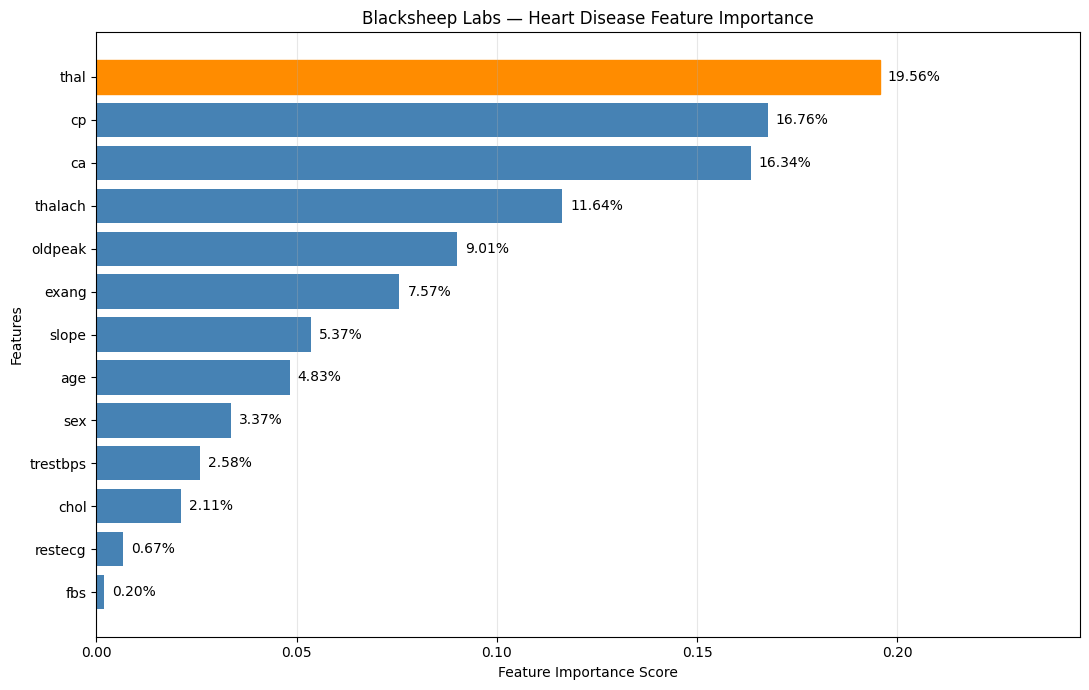

BLACKSHEEP LABS
FEATURE IMPORTANCE VISUALIZATION
--------------------------------
Most Important Feature: thal
Importance Score: 0.1956

Feature Importance Chart Created Successfully!


In [18]:
# Blacksheep Labs
# Lesson 20: Finding The Most Important Features
# Step 2 of 3 — Visualize Feature Importance

import matplotlib.pyplot as plt

# 1. Sort features for horizontal chart
plot_data = feature_importance_df.sort_values(
    by="Importance",
    ascending=True
)

# 2. Create chart
plt.figure(figsize=(11, 7))

bars = plt.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    color="steelblue"
)

# 3. Highlight the most important feature
bars[-1].set_color("darkorange")

# 4. Add percentage labels
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{width * 100:.2f}%",
        va="center"
    )

# 5. Format chart
plt.title(
    "Blacksheep Labs — Heart Disease Feature Importance"
)
plt.xlabel("Feature Importance Score")
plt.ylabel("Features")

plt.xlim(
    0,
    feature_importance_df["Importance"].max() + 0.05
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# 6. Display chart
plt.show()

# 7. Print summary
print("BLACKSHEEP LABS")
print("FEATURE IMPORTANCE VISUALIZATION")
print("--------------------------------")

print(
    "Most Important Feature:",
    feature_importance_df.iloc[0]["Feature"]
)

print(
    "Importance Score:",
    round(
        feature_importance_df.iloc[0]["Importance"],
        4
    )
)

print("\nFeature Importance Chart Created Successfully!")

BLACKSHEEP LABS
PERMUTATION FEATURE IMPORTANCE
----------------------------------------
 Feature  Importance  Std Dev
    thal      0.0545   0.0172
      ca      0.0355   0.0130
      cp      0.0215   0.0109
   exang      0.0054   0.0064
     age      0.0045   0.0039
 oldpeak      0.0041   0.0091
   slope      0.0037   0.0050
 restecg      0.0033   0.0025
    chol      0.0008   0.0055
     fbs      0.0000   0.0000
trestbps     -0.0012   0.0037
     sex     -0.0025   0.0033
 thalach     -0.0041   0.0069


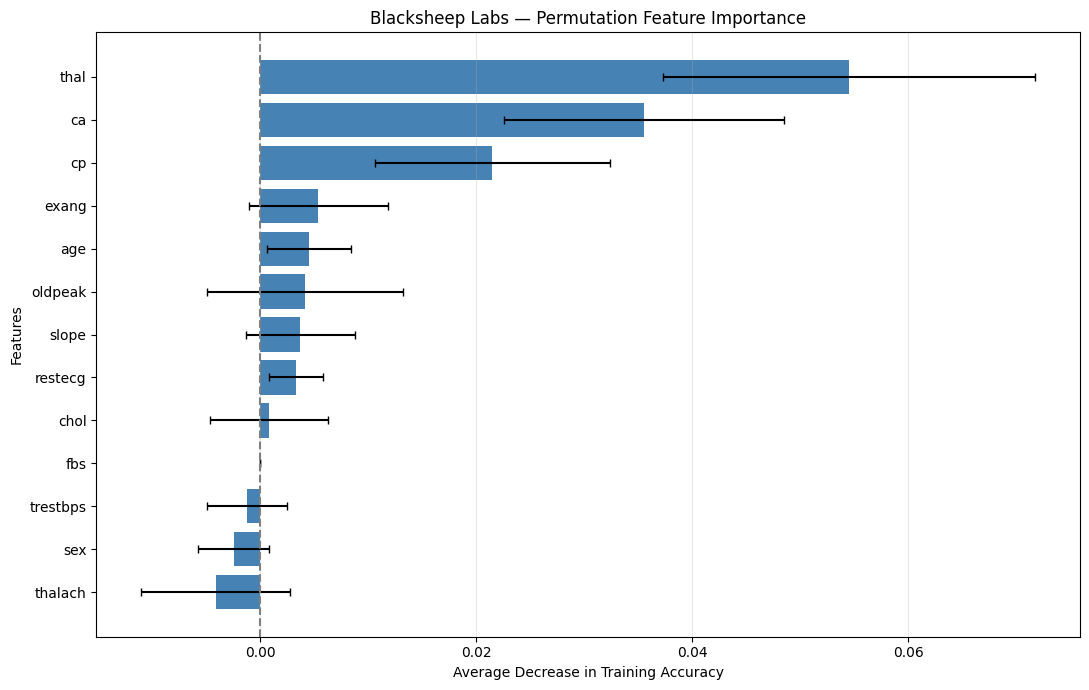


BLACKSHEEP LABS
FEATURE IMPORTANCE SUMMARY
----------------------------------------
Most Important Feature (Random Forest): thal
Most Important Feature (Permutation): thal

PERMUTATION ANALYSIS COMPLETE!


In [19]:
# Blacksheep Labs
# Lesson 20: Finding The Most Important Features
# Step 3 of 3 — Permutation Feature Importance

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# 1. Calculate permutation importance
permutation_results = permutation_importance(
    estimator=model,
    X=X_train,
    y=y_train,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

# 2. Create a results table
permutation_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": permutation_results.importances_mean,
    "Std Dev": permutation_results.importances_std
})

# 3. Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# 4. Display results
print("BLACKSHEEP LABS")
print("PERMUTATION FEATURE IMPORTANCE")
print("----------------------------------------")

print(
    permutation_df.round(4).to_string(index=False)
)

# 5. Visualize results
plot_data = permutation_df.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance"],
    xerr=plot_data["Std Dev"],
    color="steelblue",
    capsize=3
)

plt.title(
    "Blacksheep Labs — Permutation Feature Importance"
)
plt.xlabel("Average Decrease in Training Accuracy")
plt.ylabel("Features")

plt.axvline(
    x=0,
    color="gray",
    linestyle="--"
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Final summary
print("\nBLACKSHEEP LABS")
print("FEATURE IMPORTANCE SUMMARY")
print("----------------------------------------")

print(
    "Most Important Feature (Random Forest):",
    feature_importance_df.iloc[0]["Feature"]
)

print(
    "Most Important Feature (Permutation):",
    permutation_df.iloc[0]["Feature"]
)

print("\nPERMUTATION ANALYSIS COMPLETE!")